# Levenberg–Marquardt for Nonlinear Least Squares

Minimize the extended Rosenbrock function
$$f(\mathbf{x})=\frac12\sum_{i=1}^{n-1}\left[100(x_{i+1}-x_i^2)^2+(1-x_i)^2\right]=\frac12\|\mathbf{r}(\mathbf{x})\|_2^2.$$
The residuals are $r_{2i-1}=10(x_{i+1}-x_i^2)$ and $r_{2i}=1-x_i$. The global minimizer is $\mathbf{x}^\star=\mathbf{1}$, with $f(\mathbf{x}^\star)=0$.

Complete the `TODO` section, keep the interfaces unchanged, and run cells in order. Use NumPy, SciPy, and Matplotlib.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

## 1. Residuals and Jacobian (provided)
The function below returns the Rosenbrock residual vector and its sparse Jacobian.

In [2]:
def residual_jacobian(x):
    """Input: x, a vector of length n >= 2.
    Outputs: r, shape (2*n-2,); J, sparse CSR matrix (2*n-2, n).
    """
    n = len(x)
    r = np.empty(2 * (n - 1))
    r[0::2] = 10 * (x[1:] - x[:-1]**2)
    r[1::2] = 1 - x[:-1]

    i = np.arange(n - 1)
    rows = np.concatenate([2*i, 2*i, 2*i + 1])
    cols = np.concatenate([i, i + 1, i])
    values = np.concatenate([-20*x[:-1], 10*np.ones(n-1), -np.ones(n-1)])
    J = csr_matrix((values, (rows, cols)), shape=(2*(n-1), n))
    return r, J


## 2. Reuse CG from the previous problem
Copy your completed CG function from the previous problem into the cell below. Keep the interface `cg(matvec, b, epsilon, maxiter)`, returning the solution vector and iteration count. LM uses the solution vector only.

In [3]:
def cg(matvec, b, epsilon=1e-8, maxiter=2000):
    """Inputs: callable matvec(v) returning A @ v, vector b (n,),
    relative tolerance epsilon, and integer iteration limit maxiter.
    Outputs: solution x (n,) and integer iteration count.
    The matrix A is symmetric positive definite.
    """
    norm_b = np.linalg.norm(b)
    if norm_b == 0:
        return np.zeros_like(b), 0

    x = np.zeros_like(b)
    r = b.copy()
    p = r.copy()
    
    r_dot_r = np.dot(r, r)
    stop_tol = (epsilon * norm_b) ** 2

    if r_dot_r < stop_tol:
        return x, 0

    for k in range(maxiter):
        Ap = matvec(p)
        alpha = r_dot_r / np.dot(p, Ap)
        x = x + alpha * p
        r = r - alpha * Ap

        r_dot_r_next = np.dot(r, r)
        if r_dot_r_next < stop_tol:
            return x, k + 1

        beta = r_dot_r_next / r_dot_r
        p = r + beta * p
        r_dot_r = r_dot_r_next

    return x, maxiter

## 3. Implement Madsen–Nielsen LM
Complete the `TODO` section: initialization, direction computation, stopping tests, gain ratio, acceptance/rejection, and damping updates.
Use $\mathbf{g}=\mathbf{J}^\top\mathbf{r}$ and solve
$$(\mathbf{J}^\top\mathbf{J}+\mu\mathbf{I})\mathbf{d}=-\mathbf{g}$$
using CG from the previous problem. Initialize $\mu=\tau\max_i(\mathbf{J}_0^\top\mathbf{J}_0)_{ii}$ and $\nu=2$.

Compute the gain ratio using the undamped linearized model:
$$\rho=\frac{f(\mathbf{x})-f(\mathbf{x}+\mathbf{d})}{-\mathbf{g}^\top\mathbf{d}-\frac12\|\mathbf{J}\mathbf{d}\|_2^2}.$$
- If $\rho>0$, accept the point, set $\mu\leftarrow\mu\max\{1/3,1-(2\rho-1)^3\}$, and reset $\nu=2$.
- Otherwise reject, set $\mu\leftarrow\mu\nu$, then $\nu\leftarrow2\nu$.
- Nonpositive predicted reduction or nonfinite trial values cause rejection.

Stop when $\|\mathbf{g}\|_\infty\le\texttt{tol}$ or at the iteration limit.

In [ ]:
def lm(x0, tau=1e-3, tol=1e-6, maxiter=5000, cg_tol=1e-6, cg_maxiter=2000):
    """Inputs: initial vector x0; positive damping scale tau;
    outer/inner tolerances and iteration limits.
    Outputs: x (n,) and objective history (initial value plus every attempt).
    """
    x = np.array(x0, dtype=float, copy=True)
    r, J = residual_jacobian(x)
    f = 0.5 * (r @ r)
    history = [f]

    diag_JtJ = np.asarray(J.power(2).sum(axis=0)).ravel()
    mu = tau * np.max(diag_JtJ)
    nu = 2.0

    g = J.T @ r

    for _ in range(maxiter):
        if np.linalg.norm(g, ord=np.inf) <= tol:
            break

        def matvec(v):
            return J.T @ (J @ v) + mu * v

        d, _ = cg(matvec, -g, epsilon=cg_tol, maxiter=cg_maxiter)

        Jd = J @ d
        predicted_reduction = -np.dot(g, d) - 0.5 * np.dot(Jd, Jd)

        x_trial = x + d
        r_trial, J_trial = residual_jacobian(x_trial)
        f_trial = 0.5 * np.dot(r_trial, r_trial)

        if predicted_reduction > 0 and np.isfinite(f_trial):
            rho = (f - f_trial) / predicted_reduction
        else:
            rho = -1.0

        if rho > 0:
            x = x_trial
            r = r_trial
            J = J_trial
            f = f_trial
            g = J.T @ r

            mu = mu * max(1.0 / 3.0, 1.0 - (2.0 * rho - 1.0) ** 3)
            nu = 2.0
        else:
            mu = mu * nu
            nu = 2.0 * nu

        history.append(f)

    return x, np.array(history)

## 4. Experiments
Use $n=1000$, $\mathbf{x}_0=(-1.2,1,-1.2,1,\ldots)^\top$, and the three given damping scales $\tau$.

Run the cells below after completing LM. Include the completed $\texttt{lm}$ function and the final convergence plot in your written answer. 

The plot is saved as `lm_rosenbrock.pdf` in the current working directory.

In [5]:
n = 1000
tau_values = [1e-5, 1e-3, 1e-1]

tol = 1e-6
maxiter = 5000
cg_tol = 1e-6
cg_maxiter = 2000

In [6]:
results = []
x0 = np.ones(n)
x0[::2] = -1.2
print(f"{'tau':>8} {'LM iters':>9} {'time (s)':>9} {'f(x)':>11} {'|grad|inf':>11}")

for tau in tau_values:
    start = time.perf_counter()
    x, history = lm(x0, tau, tol, maxiter, cg_tol, cg_maxiter)
    elapsed = time.perf_counter() - start
    r, J = residual_jacobian(x)
    grad_norm = np.linalg.norm(J.T @ r, ord=np.inf)
    results.append(dict(tau=tau, history=history))
    print(f"{tau:8.1e} {len(history)-1:9d} {elapsed:9.3f} "
          f"{history[-1]:11.3e} {grad_norm:11.3e}")
    if grad_norm > tol:
        print("  Gradient tolerance not reached.")

     tau  LM iters  time (s)        f(x)   |grad|inf
 1.0e-05      1123     1.005   4.205e-13   7.241e-07
 1.0e-03      1120     0.932   6.992e-15   6.350e-08
 1.0e-01      1140     0.949   1.252e-15   2.481e-08


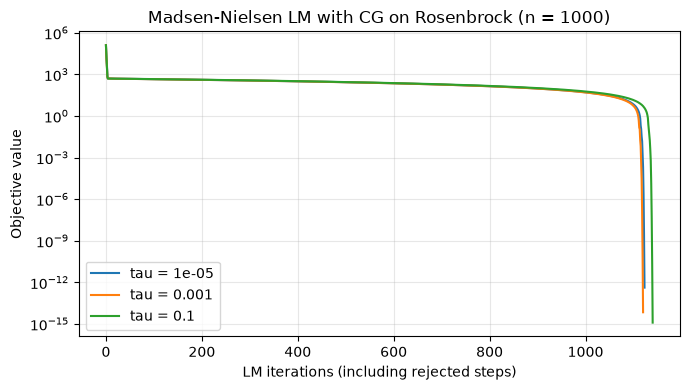

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for result in results:
    ax.semilogy(np.maximum(result["history"], np.finfo(float).tiny),
                label=f"tau = {result['tau']:g}")
ax.set_title(f"Madsen-Nielsen LM with CG on Rosenbrock (n = {n})")
ax.set_xlabel("LM iterations (including rejected steps)")
ax.set_ylabel("Objective value")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("lm_rosenbrock.pdf", bbox_inches="tight")
plt.show()